In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(DATA_DIR / "train_data.csv")
test_data = pd.read_csv(DATA_DIR / "test_data.csv")

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head())

Training dataset: (5616, 20)
Testing dataset: (1405, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No


In [3]:
TARGET_COLUMN = "Churn"

X_train = train_data.drop(columns=[TARGET_COLUMN])
y_train = train_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

X_test = test_data.drop(columns=[TARGET_COLUMN])
y_test = test_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5616, 19)
y_train: (5616,)
X_test: (1405, 19)
y_test: (1405,)


In [4]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 3
Categorical features: 16


In [5]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [6]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Naive Bayes preprocessor created successfully!")

Naive Bayes preprocessor created successfully!


In [8]:
GaussianNB(var_smoothing=1e-9)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [9]:
naive_bayes = GaussianNB(
    priors=None,
    var_smoothing=1e-9
)

print(naive_bayes)

GaussianNB()


In [10]:
naive_bayes_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", naive_bayes)
    ]
)

print("Gaussian Naive Bayes pipeline created!")

Gaussian Naive Bayes pipeline created!


In [11]:
naive_bayes_pipeline.fit(X_train, y_train)

print("Gaussian Naive Bayes training completed!")

Gaussian Naive Bayes training completed!


In [12]:
trained_nb = naive_bayes_pipeline.named_steps["classifier"]

print("Class labels:", trained_nb.classes_)
print("Class priors:", trained_nb.class_prior_)
print("Number of features:", trained_nb.n_features_in_)

Class labels: [0 1]
Class priors: [0.73557692 0.26442308]
Number of features: 46


In [13]:
y_pred = naive_bayes_pipeline.predict(X_test)

y_pred_proba = naive_bayes_pipeline.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Churn_Probability": y_pred_proba
})

display(results.head(10))

,Actual,Predicted,Churn_Probability
0,0,1,1.000000e+00
1,1,1,9.999999e-01
2,1,1,9.978134e-01
3,0,0,1.430283e-05
4,0,0,4.975649e-09
5,0,1,9.611608e-01
6,0,0,5.133799e-23
7,1,1,9.999996e-01
8,0,0,3.873270e-32
9,0,0,5.738962e-13


In [15]:
naive_bayes_metrics = {
    "Model": "Naive Bayes",

    "Accuracy": accuracy_score(y_test, y_pred),

    "AUC": roc_auc_score(y_test, y_pred_proba),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "MCC": matthews_corrcoef(y_test, y_pred)
}

naive_bayes_metrics_df = pd.DataFrame([
    naive_bayes_metrics
])

display(
    naive_bayes_metrics_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Naive Bayes,0.6847,0.8067,0.4488,0.8360,0.5840,0.4114


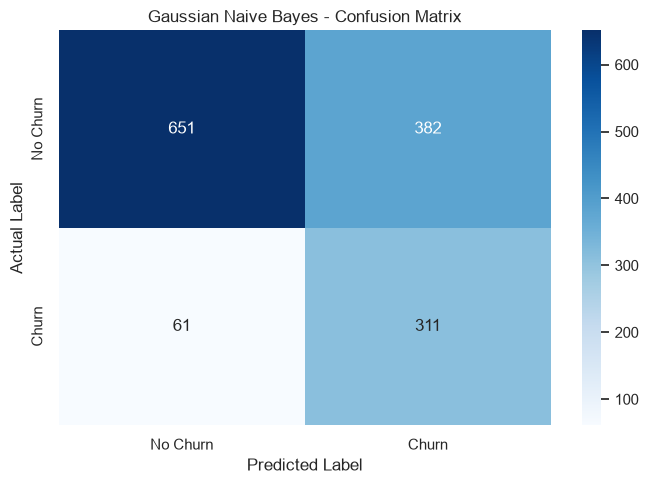

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [17]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.9143    0.6302    0.7461      1033
       Churn     0.4488    0.8360    0.5840       372

    accuracy                         0.6847      1405
   macro avg     0.6815    0.7331    0.6651      1405
weighted avg     0.7911    0.6847    0.7032      1405



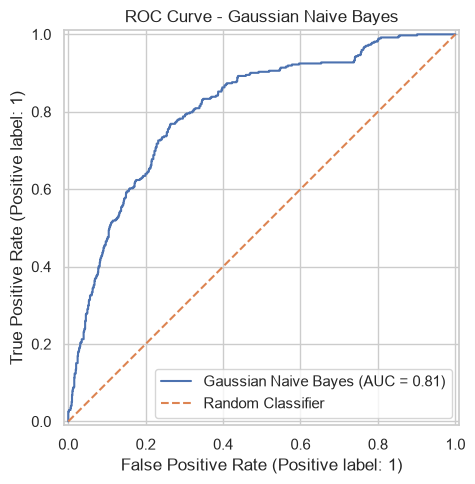

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="Gaussian Naive Bayes",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve - Gaussian Naive Bayes")
ax.legend()

plt.tight_layout()
plt.show()

In [19]:
MODEL_PATH = MODEL_DIR / "naive_bayes.joblib"

joblib.dump(
    naive_bayes_pipeline,
    MODEL_PATH
)

print("Gaussian Naive Bayes model saved successfully!")
print("Location:", MODEL_PATH)

Gaussian Naive Bayes model saved successfully!
Location: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/naive_bayes.joblib


In [20]:
naive_bayes_metrics_df.to_csv(
    RESULTS_DIR / "naive_bayes_metrics.csv",
    index=False
)

print("Naive Bayes evaluation metrics exported successfully!")

Naive Bayes evaluation metrics exported successfully!


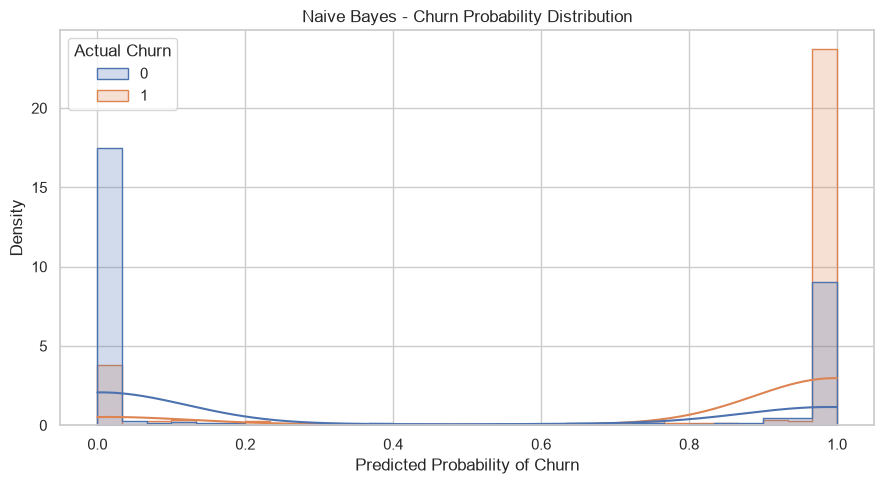

In [21]:
probability_df = pd.DataFrame({
    "Actual Churn": y_test.values,
    "Predicted Churn Probability": y_pred_proba
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=probability_df,
    x="Predicted Churn Probability",
    hue="Actual Churn",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Naive Bayes - Churn Probability Distribution")
plt.xlabel("Predicted Probability of Churn")
plt.ylabel("Density")

plt.tight_layout()
plt.show()